# Stage 7: Lows and Dips (Participant 001)

Stage 6 looked at glucose going **up**. Here we look at glucose going **down**, and bring in two new sensors from the Empatica E4 wristband to understand why:

- **HR** (heart rate): tells us about exertion, stress, and sleep
- **ACC** (accelerometer): tells us how much the wrist is moving

### Questions

**Part A: Finding lows and dips**

| # | Question |
|---|---|
| Q1 | Are there any readings below 70 mg/dL? When, and how long did they last? |
| Q2 | *(added)* What "relative dips" happen above 70, and how deep and fast are they? |

**Part B: Understanding the new sensors**

| # | Question |
|---|---|
| Q3 | *(added)* When was the wristband worn, and how well does it overlap with the CGM? |
| Q4 | *(added)* How active is the participant, and when? What is their resting heart rate? |
| Q5 | *(added)* When does the participant sleep? |

**Part C: Dips and activity**

| # | Question |
|---|---|
| Q6 | Do dips follow physical activity? (compared against ordinary times) |
| Q7 | *(added)* What happens to glucose during and after an activity bout? |
| Q8 | *(added)* Does heart rate rise when glucose drops? (the body's counter-response) |

**Part D: Dips and meals**

| # | Question |
|---|---|
| Q9 | Do dips happen after large spikes (reactive drop after a meal)? |
| Q10 | *(added)* Are some night dips likely sensor "compression lows"? |

**Part E: Putting it together**

| # | Question |
|---|---|
| Q11 | *(added)* What is the most likely cause of each dip? |

## Setup

**Glucose thresholds** follow the international CGM consensus: below 70 mg/dL is *level 1* low, below 54 mg/dL is *level 2* (clinically significant), and an *episode* needs at least 15 minutes (3 consecutive readings) below the threshold.

**Activity thresholds** use **ENMO** (Euclidean Norm Minus One), a standard way to turn raw wrist acceleration into "how much movement" (explained below). The cut-offs here (40 mg light, 100 mg moderate-to-vigorous) come from studies on other research wristbands, so treat them as approximate for the E4.

**Caching:** the raw ACC file is ~850 MB (32 samples per second). The first run summarises it to 1-minute values and saves them, which takes a few minutes. Later runs load the small saved files instantly.

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings("ignore", message="obj.round has no effect")

PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
FOOD_PATH = f"{DATA_DIR}/{PID}/Food_Log_{PID}.csv"
MEALS_PATH = f"../clean_data/meals_{PID}.csv"

HR_PATH = f"{DATA_DIR}/{PID}/HR_{PID}.csv"
ACC_PATH = f"{DATA_DIR}/{PID}/ACC_{PID}.csv"
HR_CACHE = f"hr_1min_{PID}.csv"
ACC_CACHE = f"acc_1min_{PID}.csv"

# Glucose
LOW1, LOW2 = 70, 54
MIN_EPISODE_READINGS = 3        # 15 minutes
DIP_PROMINENCE = 20             # a relative dip must be ≥ 20 mg/dL below its surroundings

# Accelerometer (E4 reports raw values in 1/64 g)
ACC_SCALE = 64
ACC_CHUNK = 2_000_000           # rows per chunk when reading the big file
LIGHT_ENMO, ACTIVE_ENMO = 40, 100   # mg
SLEEP_ENMO = 15                 # mg; very still
BOUT_MIN = 10                   # minutes of activity to count as a bout

# Windows around a dip (minutes)
LOOKBACK_ACTIVITY = 90
LOOKBACK_MEAL = 240

INTERVAL = pd.Timedelta("5min")
TIME_FIXES = {"2020-02-18 01:40:00": "2020-02-18 13:40:00"}

## Load glucose and meals

Same 5-minute glucose grid as Stages 3 and 6. Meals are rebuilt from the food log with the Stage 4 time fix, merging items logged within 30 minutes.

In [8]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")
glu = glu.sort_values("timestamp").reset_index(drop=True)

start = glu["timestamp"].iloc[0]
slot = ((glu["timestamp"] - start) / INTERVAL).round().astype(int)
grid = glu.assign(slot=slot).drop_duplicates("slot").set_index("slot")["glucose"].reindex(range(slot.max() + 1))
grid.index = start + grid.index * INTERVAL
grid.index.name = "timestamp"

food = pd.read_csv(FOOD_PATH)
food["time_begin"] = pd.to_datetime(food["time_begin"])
for old, new in TIME_FIXES.items():
    food.loc[food["time_begin"] == pd.Timestamp(old), "time_begin"] = pd.Timestamp(new)
food = food.sort_values("time_begin")

mid, cur, ids = 0, None, []
for t in food["time_begin"]:
    if cur is None or t - cur > pd.Timedelta("30min"):
        mid, cur = mid + 1, t
    ids.append(mid)
meals = food.assign(meal_id=ids).groupby("meal_id").agg(
    time=("time_begin", "min"),
    foods=("logged_food", lambda x: ", ".join(x.astype(str))),
    carbs=("total_carb", lambda x: x.sum(min_count=1)),
).reset_index(drop=True)

print("Glucose slots:", len(grid), "| meals:", len(meals))

Glucose slots: 2599 | meals: 38


## Load heart rate (1-minute summary)

The HR file has one value per second, but its `datetime` column only goes down to the minute (`2/13/20 15:29`), so ~60 rows share each timestamp. We average them into **one value per minute**, keeping the min, max, and number of samples too.

The E4 calculates HR from the optical pulse sensor (PPG). It's reliable at rest but can be noisy during strong wrist movement, and the first minute after the device starts is often unstable.

In [9]:
if os.path.exists(HR_CACHE):
    hr1 = pd.read_csv(HR_CACHE, parse_dates=["time"], index_col="time")
    print("Loaded cached 1-min HR")
else:
    hr_raw = pd.read_csv(HR_PATH)
    hr_raw.columns = [c.strip() for c in hr_raw.columns]
    hr1 = hr_raw.groupby("datetime")["hr"].agg(hr="mean", hr_min="min", hr_max="max", hr_n="count")
    hr1.index = pd.to_datetime(hr1.index, format="%m/%d/%y %H:%M")
    hr1.index.name = "time"
    hr1 = hr1.sort_index()
    hr1.to_csv(HR_CACHE)
    print(f"Summarised {len(hr_raw):,} HR samples into {len(hr1):,} minutes (saved to {HR_CACHE})")

print("HR range:", hr1.index.min(), "→", hr1.index.max())
hr1.describe().round(1)

Loaded cached 1-min HR
HR range: 2020-02-13 15:29:00 → 2020-02-22 17:56:00


,hr,hr_min,hr_max,hr_n
count,10578.0,10578.0,10578.0,10578.0
mean,73.3,69.5,77.2,60.0
std,15.8,13.6,18.3,1.4
min,47.5,46.9,47.8,3.0
25%,61.0,59.2,62.6,60.0
50%,70.2,66.8,74.0,60.0
75%,81.6,76.4,87.2,60.0
max,176.0,175.8,187.1,60.0


In [10]:
hr1.head()

,hr,hr_min,hr_max,hr_n
time,,,,
2020-02-13 15:29:00,85.130500,81.77,99.00,60
2020-02-13 15:30:00,92.563167,88.58,96.25,60
2020-02-13 15:31:00,97.772833,96.12,99.68,60
2020-02-13 15:32:00,99.167833,97.10,101.33,60
2020-02-13 15:33:00,88.638333,78.02,98.20,60


In [12]:
hr_raw

NameError: name 'hr_raw' is not defined

## Load the accelerometer (1-minute summary)

Each ACC row has three values (`acc_x`, `acc_y`, `acc_z`) in units of 1/64 g. To turn them into a single movement score:

1. **Magnitude** = √(x² + y² + z²) ÷ 64, in g. At rest this is about **1 g** (gravity alone).
2. **ENMO** = magnitude − 1 g, with negative values set to 0, reported in milli-g (mg). Removing gravity leaves only the movement.
3. Average ENMO over each minute.

We also keep the **standard deviation of the magnitude** per minute, which is useful for spotting when the wristband is lying still on a table.

The file is read in chunks, and the minute is taken straight from the first 16 characters of the timestamp text (`2020-02-13 15:28`), which is much faster than converting 27 million timestamps.

In [13]:
if os.path.exists(ACC_CACHE):
    acc1 = pd.read_csv(ACC_CACHE, parse_dates=["time"], index_col="time")
    print("Loaded cached 1-min ACC")
else:
    parts, rows = [], 0
    reader = pd.read_csv(ACC_PATH, chunksize=ACC_CHUNK,
                         dtype={"acc_x": "float32", "acc_y": "float32", "acc_z": "float32"})
    for i, ch in enumerate(reader):
        ch.columns = [c.strip() for c in ch.columns]
        mag = np.sqrt(ch["acc_x"] ** 2 + ch["acc_y"] ** 2 + ch["acc_z"] ** 2) / ACC_SCALE
        part = pd.DataFrame({
            "minute": ch["datetime"].str[:16],
            "enmo": np.clip(mag - 1, 0, None) * 1000,
            "mag": mag,
            "mag2": mag ** 2,
        }).groupby("minute").agg(enmo_sum=("enmo", "sum"), mag_sum=("mag", "sum"),
                                 mag2_sum=("mag2", "sum"), n=("mag", "size"))
        parts.append(part)
        rows += len(ch)
        print(f"  chunk {i + 1}: {rows:,} rows processed", end="\r")

    # A minute can be split across two chunks, so add the partial sums together
    tot = pd.concat(parts).groupby(level=0).sum()
    acc1 = pd.DataFrame({
        "enmo": tot["enmo_sum"] / tot["n"],
        "mag_mean": tot["mag_sum"] / tot["n"],
        "mag_sd": np.sqrt(np.clip(tot["mag2_sum"] / tot["n"] - (tot["mag_sum"] / tot["n"]) ** 2, 0, None)),
        "acc_n": tot["n"],
    })
    acc1.index = pd.to_datetime(acc1.index, format="%Y-%m-%d %H:%M")
    acc1.index.name = "time"
    acc1 = acc1.sort_index()
    acc1.to_csv(ACC_CACHE)
    print(f"\nSummarised {rows:,} ACC samples into {len(acc1):,} minutes (saved to {ACC_CACHE})")

print("ACC range:", acc1.index.min(), "→", acc1.index.max())
print(f"Median magnitude: {acc1['mag_mean'].median():.3f} g  (should be close to 1.0; if not, check ACC_SCALE)")
acc1.describe().round(3)

  chunk 11: 20,296,428 rows processed
Summarised 20,296,428 ACC samples into 10,580 minutes (saved to acc_1min_001.csv)
ACC range: 2020-02-13 15:28:00 → 2020-02-22 17:56:00
Median magnitude: 1.000 g  (should be close to 1.0; if not, check ACC_SCALE)


,enmo,mag_mean,mag_sd,acc_n
count,10580.000,10580.000,10580.000,10580.000
mean,18.923,1.000,0.054,1918.377
std,24.342,0.016,0.062,46.414
min,0.000,0.970,0.000,124.000
25%,2.348,0.989,0.006,1920.000
50%,11.233,1.000,0.032,1920.000
75%,26.965,1.009,0.086,1920.000
max,265.020,1.203,0.508,1920.000


In [14]:
# Combine HR and ACC on one regular 1-minute timeline
t_min = min(hr1.index.min(), acc1.index.min())
t_max = max(hr1.index.max(), acc1.index.max())
minutes = pd.date_range(t_min.floor("min"), t_max.floor("min"), freq="1min")
wear = pd.DataFrame(index=minutes).join(hr1[["hr"]]).join(acc1[["enmo", "mag_sd"]])
wear.index.name = "time"

# Smoothed versions used throughout
wear["enmo_5"] = wear["enmo"].rolling(5, center=True, min_periods=3).mean()
wear["enmo_30"] = wear["enmo"].rolling(30, center=True, min_periods=15).mean()
wear["hr_5"] = wear["hr"].rolling(5, center=True, min_periods=3).mean()
print("Minutes on the combined timeline:", len(wear))

Minutes on the combined timeline: 13109


---
# Part A: Finding lows and dips

## Q1: Readings below 70 mg/dL

We list every run of consecutive readings below 70 and below 54. A run only counts as a clinical **episode** if it lasts at least 15 minutes. Shorter runs are often sensor noise or a brief real dip.

We also look at time spent between 70 and 80 mg/dL, the "near-low" zone, which shows how often glucose approaches the low range without crossing it.

In [15]:
def runs_below(series, thr):
    """One row per run of consecutive readings below thr."""
    below = series < thr
    run_id = (below != below.shift()).cumsum()
    rows = [{"start": s.index.min(), "end": s.index.max(), "nadir": s.min(), "readings": s.count()}
            for _, s in series[below].groupby(run_id[below])]
    out = pd.DataFrame(rows, columns=["start", "end", "nadir", "readings"])
    out["start"] = pd.to_datetime(out["start"])
    out["end"] = pd.to_datetime(out["end"])
    out["duration_min"] = out["readings"] * 5
    out["episode"] = out["readings"] >= MIN_EPISODE_READINGS
    out["hour"] = out["start"].dt.hour
    return out

low70 = runs_below(grid, LOW1)
low54 = runs_below(grid, LOW2)

valid = grid.dropna()
print(f"Readings < {LOW1}: {(valid < LOW1).sum()}  ({(valid < LOW1).mean() * 100:.2f}% of time)")
print(f"Readings < {LOW2}: {(valid < LOW2).sum()}  ({(valid < LOW2).mean() * 100:.2f}% of time)")
print(f"Readings 70–80 (near-low): {valid.between(70, 80, inclusive='left').sum()}  "
      f"({valid.between(70, 80, inclusive='left').mean() * 100:.1f}% of time)")
print(f"\nRuns below {LOW1}: {len(low70)}  | clinical episodes (≥ 15 min): {int(low70['episode'].sum())}")
print(f"Runs below {LOW2}: {len(low54)}  | clinical episodes (≥ 15 min): {int(low54['episode'].sum())}")
low70

Readings < 70: 22  (0.86% of time)
Readings < 54: 3  (0.12% of time)
Readings 70–80 (near-low): 31  (1.2% of time)

Runs below 70: 4  | clinical episodes (≥ 15 min): 3
Runs below 54: 1  | clinical episodes (≥ 15 min): 1


,start,end,nadir,readings,duration_min,episode,hour
0,2020-02-13 17:23:32,2020-02-13 18:08:32,58.0,10,50,True,17
1,2020-02-14 04:23:32,2020-02-14 04:28:32,66.0,2,10,False,4
2,2020-02-15 08:38:32,2020-02-15 08:53:32,62.0,4,20,True,8
3,2020-02-16 07:58:32,2020-02-16 08:23:32,46.0,6,30,True,7


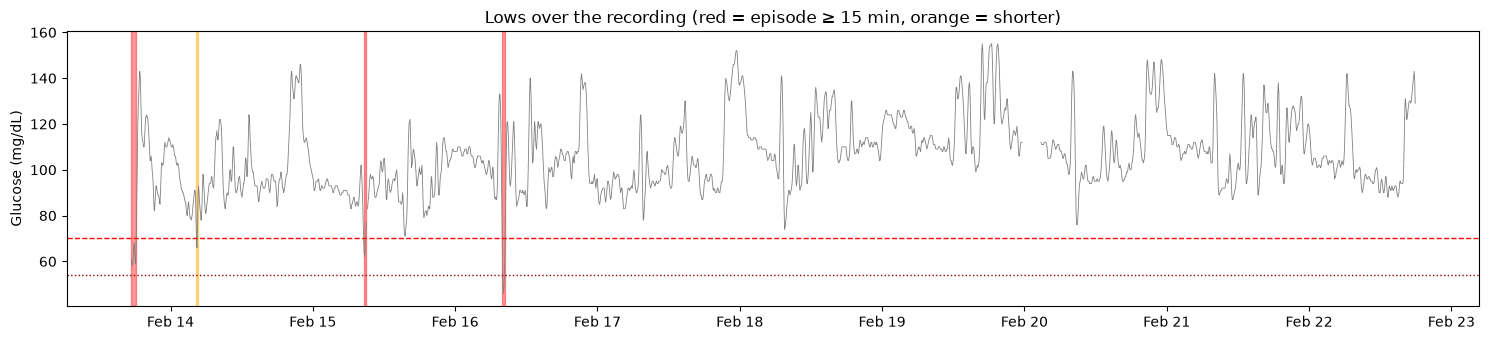

In [16]:
if len(low70):
    fig, ax = plt.subplots(figsize=(15, 3.5))
    ax.plot(grid.index, grid.values, lw=0.6, color="gray")
    for _, r in low70.iterrows():
        ax.axvspan(r["start"] - pd.Timedelta("5min"), r["end"] + pd.Timedelta("5min"),
                   color="red" if r["episode"] else "orange", alpha=0.4)
    ax.axhline(LOW1, color="red", ls="--", lw=1)
    ax.axhline(LOW2, color="darkred", ls=":", lw=1)
    ax.set_ylabel("Glucose (mg/dL)")
    ax.set_title("Lows over the recording (red = episode ≥ 15 min, orange = shorter)")
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    plt.tight_layout()
    plt.show()
else:
    print("No readings below 70 mg/dL.")

## Q2 (added): Relative dips

People without diabetes rarely go below 70, so absolute lows alone give very few events. A **relative dip** is a trough that sits at least `DIP_PROMINENCE` (20) mg/dL below the surrounding curve, wherever it happens.

For each dip we measure:
- **drop**: the highest glucose in the 2 hours before minus the nadir (lowest point)
- **fall rate**: the steepest 5-minute fall in the 30 minutes before the nadir
- **rebound**: how much glucose rises in the 30 minutes after the nadir

A slow drift down and a slow recovery looks physiological. A very sharp fall with an equally sharp rebound can point to a sensor artifact (tested in Q10).

In [17]:
filled = grid.interpolate(limit_area="inside").dropna()
idx, props = find_peaks(-filled.values, prominence=DIP_PROMINENCE, distance=12)

dips = pd.DataFrame({"nadir_time": filled.index[idx], "nadir": filled.values[idx],
                     "prominence": props["prominences"]})
dips = dips[grid.reindex(dips["nadir_time"]).notna().values].reset_index(drop=True)

rate = grid.diff() / 5
rows = []
for t, v in zip(dips["nadir_time"], dips["nadir"]):
    before = grid[t - pd.Timedelta("2h"): t]
    after = grid[t: t + pd.Timedelta("30min")]
    rows.append({
        "pre_max": before.max(),
        "pre_max_time": before.idxmax(),
        "drop": before.max() - v,
        "max_fall_rate": rate[t - pd.Timedelta("30min"): t].min(),
        "rebound_30min": after.max() - v,
    })
dips = pd.concat([dips, pd.DataFrame(rows)], axis=1)
dips["hour"] = dips["nadir_time"].dt.hour
dips["night"] = dips["hour"] < 6
dips["below_70"] = dips["nadir"] < LOW1

print(f"Relative dips: {len(dips)}  ({len(dips) / grid.index.normalize().nunique():.1f} per day)")
print(f"  of which below 70: {int(dips['below_70'].sum())}")
print(f"  at night (00–06):  {int(dips['night'].sum())}")
dips[["nadir_time", "nadir", "prominence", "drop", "max_fall_rate", "rebound_30min", "hour"]].round(1)

Relative dips: 45  (4.5 per day)
  of which below 70: 3
  at night (00–06):  3


,nadir_time,nadir,prominence,drop,max_fall_rate,rebound_30min,hour
0,2020-02-13 21:18:32,82.0,32.0,42.0,-1.2,11.0,21
1,2020-02-14 04:28:32,66.0,77.0,25.0,-2.2,27.0,4
2,2020-02-14 09:13:32,83.0,39.0,39.0,-1.6,7.0,9
3,2020-02-14 12:03:32,88.0,22.0,22.0,-0.6,13.0,12
4,2020-02-14 17:58:32,84.0,40.0,14.0,-0.8,12.0,17
5,2020-02-15 08:43:32,62.0,71.0,40.0,-1.8,21.0,8
6,2020-02-15 15:33:32,71.0,34.0,29.0,-1.4,35.0,15
7,2020-02-15 18:43:32,79.0,43.0,30.0,-1.6,3.0,18
8,2020-02-16 06:43:32,87.0,27.0,17.0,-1.2,21.0,6
9,2020-02-16 08:08:32,46.0,100.0,87.0,-4.2,65.0,8


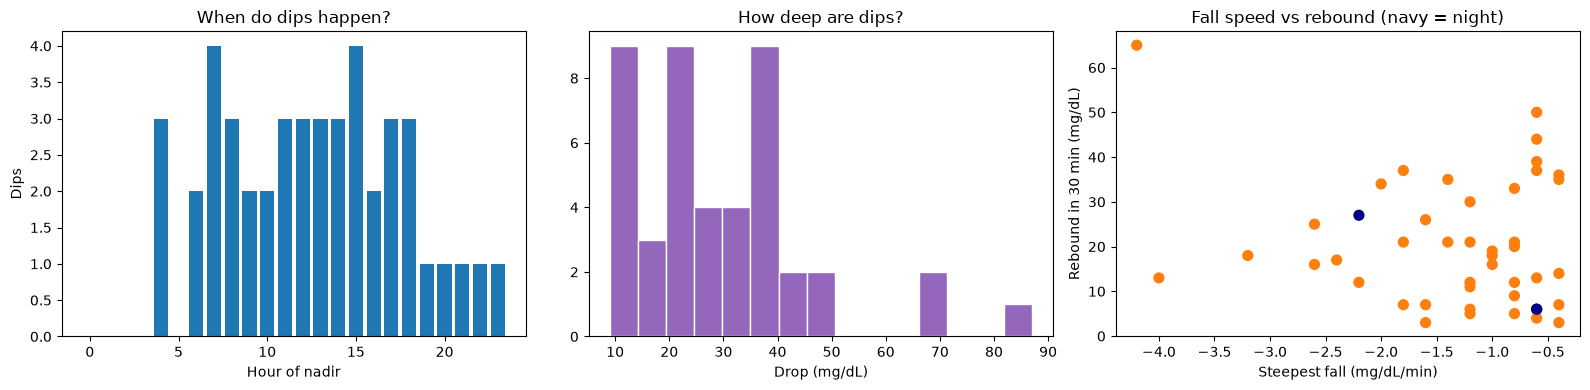

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(range(24), dips.groupby("hour").size().reindex(range(24), fill_value=0), color="tab:blue")
axes[0].set_xlabel("Hour of nadir")
axes[0].set_ylabel("Dips")
axes[0].set_title("When do dips happen?")

axes[1].hist(dips["drop"], bins=15, color="tab:purple", edgecolor="white")
axes[1].set_xlabel("Drop (mg/dL)")
axes[1].set_title("How deep are dips?")

axes[2].scatter(dips["max_fall_rate"], dips["rebound_30min"], c=np.where(dips["night"], "navy", "tab:orange"), s=50)
axes[2].set_xlabel("Steepest fall (mg/dL/min)")
axes[2].set_ylabel("Rebound in 30 min (mg/dL)")
axes[2].set_title("Fall speed vs rebound (navy = night)")
plt.tight_layout()
plt.show()

---
# Part B: Understanding the new sensors

## Q3 (added): Wristband wear time and overlap with the CGM

The CGM is worn continuously, but the E4 wristband had to be taken off to charge and upload data, so there will be gaps. Any analysis that combines glucose with HR or ACC only works where **both** devices were recording.

A minute counts as "possibly off-wrist" if the wristband was almost perfectly still for an hour (no tiny movements at all, which even sleeping wrists produce).

In [19]:
still = wear["mag_sd"] < 0.004
wear["off_wrist"] = still.rolling(60, center=True, min_periods=30).mean() > 0.95
wear["worn"] = wear["hr"].notna() & wear["enmo"].notna() & ~wear["off_wrist"]

cgm_valid = grid.dropna()
cov = pd.DataFrame({
    "CGM hours": cgm_valid.groupby(cgm_valid.index.date).size() * 5 / 60,
    "HR hours": wear["hr"].notna().groupby(wear.index.date).sum() / 60,
    "ACC hours": wear["enmo"].notna().groupby(wear.index.date).sum() / 60,
    "worn hours": wear["worn"].groupby(wear.index.date).sum() / 60,
}).fillna(0).round(1)
cov.index.name = "date"

overlap = wear["worn"].reindex(cgm_valid.index.floor("min")).fillna(False).astype(bool)
print(f"CGM readings with the wristband worn at the same time: {overlap.mean() * 100:.1f}%")
cov

CGM readings with the wristband worn at the same time: 80.0%


,CGM hours,HR hours,ACC hours,worn hours
date,,,,
2020-02-13,6.7,8.5,8.5,8.5
2020-02-14,24.0,24.0,24.0,24.0
2020-02-15,23.9,13.3,13.3,13.3
2020-02-16,24.0,7.9,7.9,7.9
2020-02-17,24.0,23.2,23.2,23.2
2020-02-18,24.0,24.0,24.0,23.7
2020-02-19,23.7,19.0,19.0,19.0
2020-02-20,21.2,24.0,24.0,24.0
2020-02-21,24.0,14.5,14.5,14.5


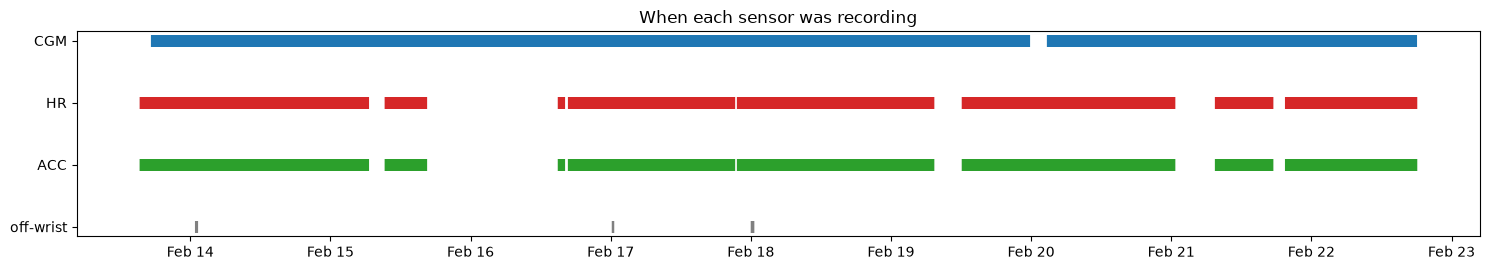

In [20]:
fig, ax = plt.subplots(figsize=(15, 2.8))
def bar(series_index, y, color, label):
    ts = pd.Series(1, index=series_index)
    ax.scatter(ts.index, np.full(len(ts), y), marker="|", s=80, color=color, label=label)

bar(grid.dropna().index, 3, "tab:blue", "CGM")
bar(wear.index[wear["hr"].notna()], 2, "tab:red", "HR")
bar(wear.index[wear["enmo"].notna()], 1, "tab:green", "ACC")
bar(wear.index[wear["off_wrist"].fillna(False).astype(bool)], 0, "gray", "possibly off-wrist")
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["off-wrist", "ACC", "HR", "CGM"])
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("When each sensor was recording")
plt.tight_layout()
plt.show()

## Q4 (added): Activity level and resting heart rate

For each day we calculate:
- **active minutes**: minutes with ENMO ≥ 100 mg (moderate-to-vigorous, e.g. brisk walking)
- **light minutes**: ENMO 40–100 mg (e.g. housework, slow walking)
- **mean HR** while worn
- **resting HR**: the 5th percentile of 1-minute HR, a simple estimate of the lowest sustained heart rate

We also find **activity bouts**: at least `BOUT_MIN` (10) minutes in a row with 5-minute average ENMO ≥ 100 mg. These are the periods most likely to affect glucose.

In [21]:
w = wear[wear["worn"]]
daily_act = pd.DataFrame({
    "worn hours": w["enmo"].groupby(w.index.date).size() / 60,
    "active min": (w["enmo"] >= ACTIVE_ENMO).groupby(w.index.date).sum(),
    "light min": w["enmo"].between(LIGHT_ENMO, ACTIVE_ENMO, inclusive="left").groupby(w.index.date).sum(),
    "mean ENMO (mg)": w["enmo"].groupby(w.index.date).mean(),
    "mean HR": w["hr"].groupby(w.index.date).mean(),
    "resting HR": w["hr"].groupby(w.index.date).quantile(0.05),
    "max HR (1-min)": w["hr"].groupby(w.index.date).max(),
}).round(1)
daily_act.index.name = "date"
resting_hr = w["hr"].quantile(0.05)
print(f"Overall resting HR (5th percentile): {resting_hr:.0f} bpm")
daily_act

Overall resting HR (5th percentile): 55 bpm


,worn hours,active min,light min,mean ENMO (mg),mean HR,resting HR,max HR (1-min)
date,,,,,,,
2020-02-13,8.5,8,68,22.6,74.9,60.3,118.9
2020-02-14,24.0,5,92,17.5,74.5,55.9,136.0
2020-02-15,13.3,16,119,22.3,72.5,52.6,135.3
2020-02-16,7.9,6,46,18.1,76.1,54.7,176.0
2020-02-17,23.2,30,237,21.9,78.0,53.9,169.6
2020-02-18,23.7,5,129,16.0,71.0,53.2,129.3
2020-02-19,19.0,2,48,11.8,68.3,55.3,141.6
2020-02-20,24.0,22,167,19.8,73.2,54.7,148.6
2020-02-21,14.5,28,135,25.7,77.1,60.4,144.4


In [22]:
# Activity bouts
active = (wear["enmo_5"] >= ACTIVE_ENMO) & wear["worn"]
run_id = (active != active.shift()).cumsum()
bouts = wear[active].groupby(run_id[active]).agg(
    start=("enmo", lambda s: s.index.min()),
    end=("enmo", lambda s: s.index.max()),
    minutes=("enmo", "size"),
    mean_enmo=("enmo", "mean"),
    mean_hr=("hr", "mean"),
    max_hr=("hr", "max"),
).reset_index(drop=True)
bouts = bouts[bouts["minutes"] >= BOUT_MIN].reset_index(drop=True)
bouts["hr_above_rest"] = bouts["mean_hr"] - resting_hr
bouts["hour"] = bouts["start"].dt.hour
print(f"Activity bouts (≥ {BOUT_MIN} min): {len(bouts)}")
bouts.round(1)

Activity bouts (≥ 10 min): 6


,start,end,minutes,mean_enmo,mean_hr,max_hr,hr_above_rest,hour
0,2020-02-15 15:02:00,2020-02-15 15:11:00,10,116.5,113.0,119.8,58.4,15
1,2020-02-17 17:00:00,2020-02-17 17:09:00,10,150.2,105.4,116.0,50.8,17
2,2020-02-20 08:21:00,2020-02-20 08:30:00,10,179.3,123.3,132.0,68.7,8
3,2020-02-21 08:21:00,2020-02-21 08:32:00,12,169.9,117.0,131.4,62.4,8
4,2020-02-21 15:01:00,2020-02-21 15:12:00,12,166.3,116.0,124.4,61.4,15
5,2020-02-22 08:25:00,2020-02-22 08:35:00,11,171.9,122.5,131.7,67.9,8


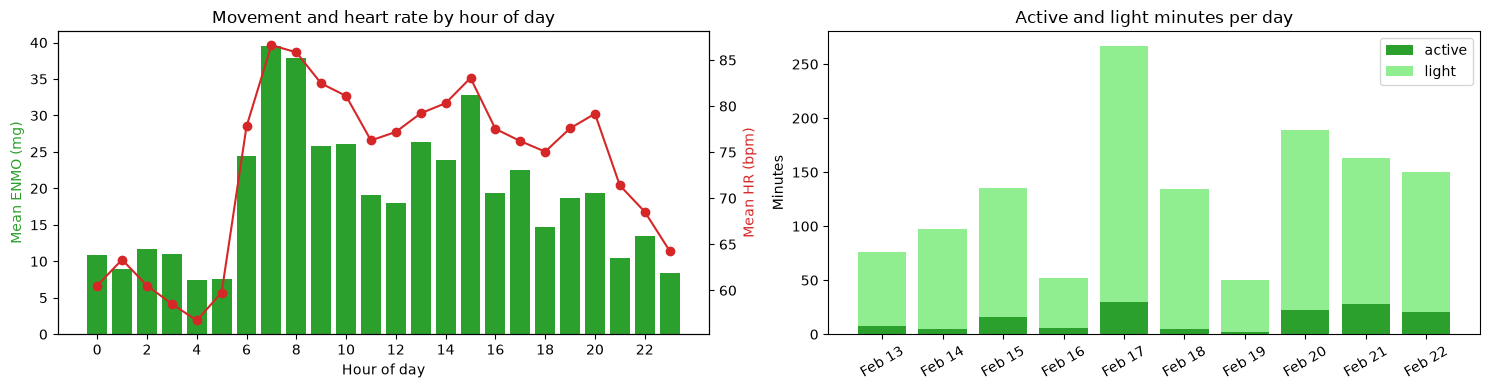

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
hourly = w.groupby(w.index.hour)[["enmo", "hr"]].mean()
axes[0].bar(hourly.index, hourly["enmo"], color="tab:green")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean ENMO (mg)", color="tab:green")
ax2 = axes[0].twinx()
ax2.plot(hourly.index, hourly["hr"], "o-", color="tab:red")
ax2.set_ylabel("Mean HR (bpm)", color="tab:red")
axes[0].set_title("Movement and heart rate by hour of day")
axes[0].set_xticks(range(0, 24, 2))

axes[1].bar([f"{d:%b %d}" for d in daily_act.index], daily_act["active min"], color="tab:green", label="active")
axes[1].bar([f"{d:%b %d}" for d in daily_act.index], daily_act["light min"], bottom=daily_act["active min"],
            color="lightgreen", label="light")
axes[1].set_ylabel("Minutes")
axes[1].set_title("Active and light minutes per day")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## Q5 (added): When does the participant sleep?

Wrist-worn devices estimate sleep from **stillness**. A minute is "sleep-like" if the 30-minute average ENMO is below `SLEEP_ENMO` (15 mg) between 21:00 and 11:00. For each night, short breaks (up to 15 min, e.g. turning over) are bridged, and the **longest still block** is taken as the main sleep period.

This is a rough estimate: lying still while awake looks the same as sleep to an accelerometer. Resting HR during this period should be among the lowest of the day, which helps confirm it.

In [25]:
def fill_short_gaps(b, max_gap):
    """Turn short runs of False that sit between True values into True."""
    b = b.astype(bool).copy()
    rid = (b != b.shift()).cumsum()
    for _, seg in b.groupby(rid):
        if not seg.iloc[0] and len(seg) <= max_gap and seg.index[0] != b.index[0] and seg.index[-1] != b.index[-1]:
            b.loc[seg.index] = True
    return b

def true_runs(b):
    """List (start, end, length) for each run of True values."""
    rid = (b != b.shift()).cumsum()
    return [(seg.index[0], seg.index[-1], len(seg)) for _, seg in b.groupby(rid) if seg.iloc[0]]

hour = wear.index.hour
sleep_like = (wear["enmo_30"] < SLEEP_ENMO) & ((hour >= 21) | (hour < 11)) & wear["worn"]
night_of = (wear.index - pd.Timedelta("12h")).date

sleep_rows = []
for n, s in sleep_like.groupby(night_of):
    runs = true_runs(fill_short_gaps(s, 15))
    if not runs:
        continue
    onset, wake, length = max(runs, key=lambda r: r[2])
    if length < 120:          # ignore blocks shorter than 2 h
        continue
    seg = wear.loc[onset:wake]
    sleep_rows.append({"night_of": n, "onset_ts": onset, "wake_ts": wake, "hours": length / 60,
                       "sleep HR": seg["hr"].mean(),
                       "sleep glucose": grid[onset:wake].mean(),
                       "sleep glucose SD": grid[onset:wake].std()})

sleep = pd.DataFrame(sleep_rows).set_index("night_of") if sleep_rows else pd.DataFrame()
if len(sleep):
    print(f"Nights with a detected sleep period: {len(sleep)}")
    print(f"Average sleep period: {sleep['hours'].mean():.1f} h")
    display_sleep = sleep.assign(onset=sleep["onset_ts"].dt.strftime("%H:%M"),
                                 wake=sleep["wake_ts"].dt.strftime("%H:%M")) \
                         .drop(columns=["onset_ts", "wake_ts"]).round(1)
else:
    display_sleep = "No sleep periods detected"
display_sleep

Nights with a detected sleep period: 8
Average sleep period: 3.5 h


,hours,sleep HR,sleep glucose,sleep glucose SD,onset,wake
night_of,,,,,,
2020-02-13,2.2,59.5,84.9,7.8,03:54,06:07
2020-02-14,3.6,58.1,90.8,1.9,02:44,06:21
2020-02-16,5.8,58.3,91.2,4.3,23:50,05:39
2020-02-17,3.7,58.7,108.8,3.2,02:04,05:47
2020-02-18,2.9,67.6,123.0,2.4,00:13,03:06
2020-02-19,3.3,58.5,110.8,3.3,22:48,02:06
2020-02-20,2.8,69.9,136.4,7.3,21:00,23:45
2020-02-21,4.0,60.5,110.3,9.4,22:25,02:22


In [26]:
# Mark each 1-minute row as asleep or not, for later questions
wear["asleep"] = False
if len(sleep):
    for _, r in sleep.iterrows():
        wear.loc[r["onset_ts"]:r["wake_ts"], "asleep"] = True

asleep_at_cgm = wear["asleep"].reindex(grid.index.floor("min")).fillna(False).astype(bool).values
if asleep_at_cgm.any():
    print(f"Glucose asleep: mean {grid[asleep_at_cgm].mean():.1f}, SD {grid[asleep_at_cgm].std():.1f}")
    print(f"Glucose awake:  mean {grid[~asleep_at_cgm].mean():.1f}, SD {grid[~asleep_at_cgm].std():.1f}")

Glucose asleep: mean 105.2, SD 16.9
Glucose awake:  mean 106.2, SD 15.6


### A tool for looking at any time window

The rest of this notebook keeps asking "what was happening around this moment?". This helper plots glucose (with meals), heart rate, and movement for any window, all on the same time axis.

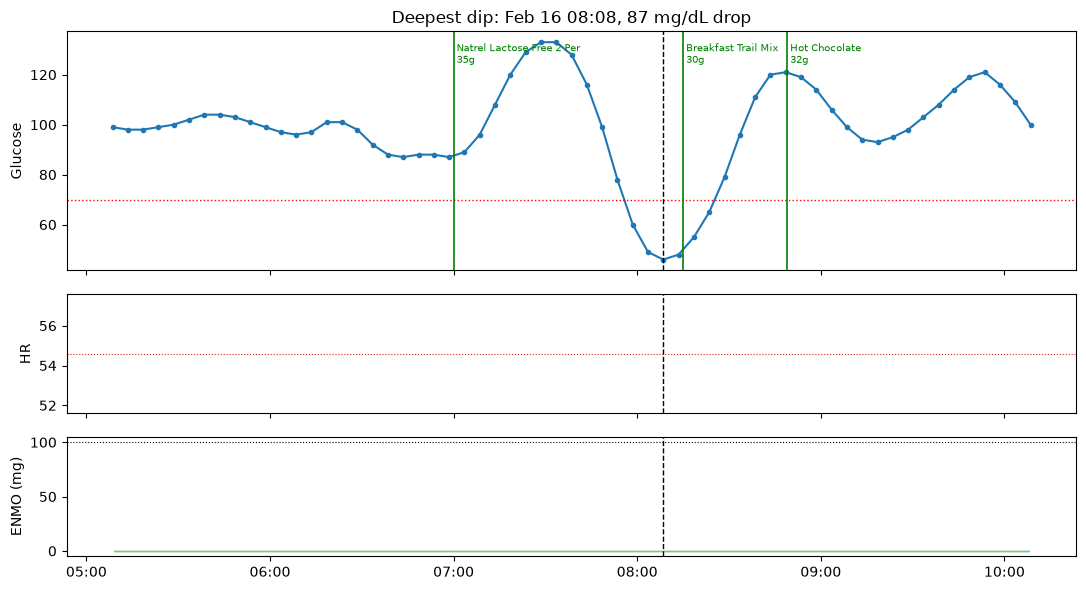

In [27]:
def plot_context(center, before=180, after=120, title="", mark=None):
    t0 = center - pd.Timedelta(minutes=before)
    t1 = center + pd.Timedelta(minutes=after)
    fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})

    g = grid[t0:t1]
    axes[0].plot(g.index, g.values, "o-", ms=3, color="tab:blue")
    axes[0].axhline(LOW1, color="red", ls=":", lw=1)
    for _, m in meals[(meals["time"] >= t0) & (meals["time"] <= t1)].iterrows():
        axes[0].axvline(m["time"], color="green", lw=1.2)
        axes[0].text(m["time"], g.max() if g.count() else 100, f" {str(m['foods'])[:25]}\n {m['carbs']:.0f}g",
                     fontsize=7, color="green", va="top")
    axes[0].set_ylabel("Glucose")

    wv = wear.loc[t0:t1]
    axes[1].plot(wv.index, wv["hr"], color="tab:red", lw=0.8)
    axes[1].axhline(resting_hr, color="tab:red", ls=":", lw=0.8)
    axes[1].set_ylabel("HR")

    axes[2].fill_between(wv.index, wv["enmo"].fillna(0), color="tab:green", alpha=0.6)
    axes[2].axhline(ACTIVE_ENMO, color="black", ls=":", lw=0.8)
    axes[2].set_ylabel("ENMO (mg)")
    if wv["asleep"].any():
        for ax in axes:
            ax.fill_between(wv.index, 0, 1, where=wv["asleep"], transform=ax.get_xaxis_transform(),
                            color="navy", alpha=0.08)

    for ax in axes:
        ax.axvline(mark if mark is not None else center, color="black", ls="--", lw=1)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[0].set_title(title or f"Context around {center:%b %d %H:%M} (blue shading = asleep)")
    plt.tight_layout()
    plt.show()

# Example: the deepest dip
if len(dips):
    d = dips.loc[dips["drop"].idxmax()]
    plot_context(d["nadir_time"], title=f"Deepest dip: {d['nadir_time']:%b %d %H:%M}, {d['drop']:.0f} mg/dL drop")

---
# Part C: Dips and activity

## Q6: Do dips follow physical activity?

Muscles take up glucose during exercise, so activity can lower glucose. To test this fairly we need a **comparison**: activity before dips might look high just because people move a lot during the day anyway.

For each dip we measure the mean ENMO, active minutes, and mean HR in the `LOOKBACK_ACTIVITY` (90) minutes before the nadir. We do the same for **control times**: all other CGM timestamps that are at least 2 hours away from any dip. Then we compare:
1. dips vs all control times
2. each dip vs control times **at the same hour of day** (±1 h), giving a percentile. A dip at the 90th percentile had more activity before it than 90% of ordinary moments at that time of day.

In [28]:
def activity_before(t, minutes=LOOKBACK_ACTIVITY):
    seg = wear.loc[t - pd.Timedelta(minutes=minutes): t]
    seg = seg[seg["worn"]]
    if len(seg) < minutes * 0.6:
        return np.nan, np.nan, np.nan
    return seg["enmo"].mean(), (seg["enmo"] >= ACTIVE_ENMO).sum(), seg["hr"].mean()

act_cols = ["enmo_before", "active_min_before", "hr_before"]
dips[act_cols] = pd.DataFrame([activity_before(t) for t in dips["nadir_time"]], columns=act_cols, index=dips.index)

# Control times: every 30 min, away from dips
cand = grid.dropna().index[::6]
far = np.array([np.min(np.abs((dips["nadir_time"] - t).dt.total_seconds())) > 7200 if len(dips) else True for t in cand])
controls = pd.DataFrame({"time": cand[far]})
controls[act_cols] = pd.DataFrame([activity_before(t) for t in controls["time"]], columns=act_cols, index=controls.index)
controls = controls.dropna()
controls["hour"] = controls["time"].dt.hour
print(f"Dips with wristband data: {dips['enmo_before'].notna().sum()} of {len(dips)} | control times: {len(controls)}")

Dips with wristband data: 33 of 45 | control times: 141


In [29]:
cmp = pd.DataFrame({
    "dips (median)": dips[["enmo_before", "active_min_before", "hr_before"]].median(),
    "controls (median)": controls[["enmo_before", "active_min_before", "hr_before"]].median(),
})
pv = {}
for c in cmp.index:
    a, b = dips[c].dropna(), controls[c].dropna()
    pv[c] = stats.mannwhitneyu(a, b).pvalue if len(a) >= 3 and len(b) >= 3 else np.nan
cmp["p (Mann–Whitney)"] = pd.Series(pv)
cmp.round(3)

,dips (median),controls (median),p (Mann–Whitney)
enmo_before,20.655,13.672,0.000
active_min_before,0.000,0.000,0.006
hr_before,77.475,67.917,0.002


Median hour-matched activity percentile of dips: 65
(50 = typical; well above 50 means dips tend to follow more activity than usual for that hour)
Dips after unusually high activity (≥ 80th percentile): 14


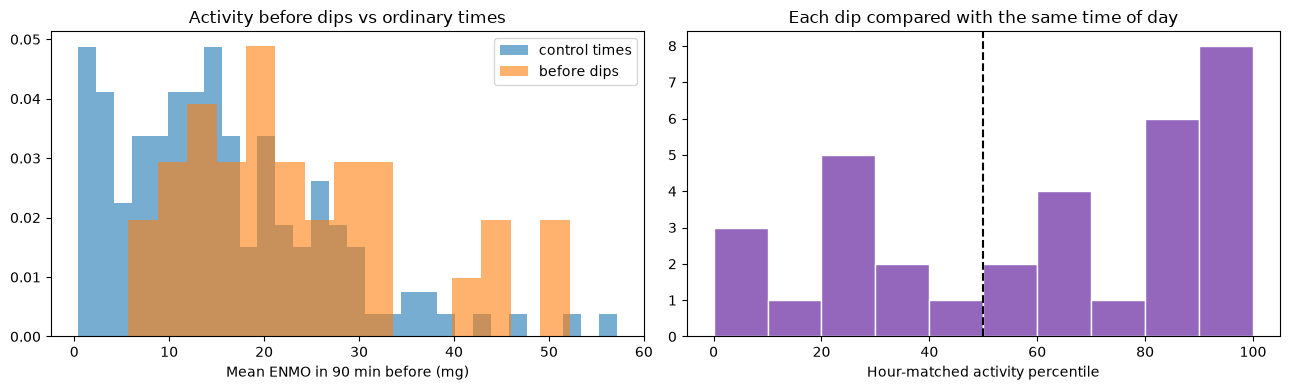

In [30]:
def hour_matched_pct(row):
    if pd.isna(row["enmo_before"]):
        return np.nan
    h = row["hour"]
    pool = controls[((controls["hour"] - h) % 24).isin([23, 0, 1])]["enmo_before"]
    return stats.percentileofscore(pool, row["enmo_before"]) if len(pool) >= 5 else np.nan

dips["activity_percentile"] = dips.apply(hour_matched_pct, axis=1)
print(f"Median hour-matched activity percentile of dips: {dips['activity_percentile'].median():.0f}")
print("(50 = typical; well above 50 means dips tend to follow more activity than usual for that hour)")
print(f"Dips after unusually high activity (≥ 80th percentile): {(dips['activity_percentile'] >= 80).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(controls["enmo_before"], bins=30, alpha=0.6, density=True, label="control times")
axes[0].hist(dips["enmo_before"].dropna(), bins=15, alpha=0.6, density=True, label="before dips")
axes[0].set_xlabel(f"Mean ENMO in {LOOKBACK_ACTIVITY} min before (mg)")
axes[0].set_title("Activity before dips vs ordinary times")
axes[0].legend()
axes[1].hist(dips["activity_percentile"].dropna(), bins=10, range=(0, 100), color="tab:purple", edgecolor="white")
axes[1].axvline(50, color="black", ls="--")
axes[1].set_xlabel("Hour-matched activity percentile")
axes[1].set_title("Each dip compared with the same time of day")
plt.tight_layout()
plt.show()

## Q7 (added): Glucose during and after activity bouts

Now we flip the question around: instead of starting from dips and looking back, we start from **activity bouts** and look forward. For each bout we take glucose just before it starts as the baseline, then track the change over the next 2 hours.

Meals complicate this: a walk right after lunch combines a meal rise with an activity fall. Bouts with a meal in the hour before or during them are flagged.

In [31]:
bout_rows = []
for _, b in bouts.iterrows():
    t = b["start"]
    base = grid[t - pd.Timedelta("15min"): t].median()
    after = grid[t: t + pd.Timedelta("2h")]
    if pd.isna(base) or after.count() < 12:
        continue
    near_meal = ((meals["time"] >= t - pd.Timedelta("60min")) & (meals["time"] <= b["end"])).any()
    bout_rows.append({
        "start": t, "minutes": b["minutes"], "mean_enmo": b["mean_enmo"], "hr_above_rest": b["hr_above_rest"],
        "baseline": base,
        "change_30": grid.asof(t + pd.Timedelta("30min")) - base,
        "change_60": grid.asof(t + pd.Timedelta("60min")) - base,
        "change_120": grid.asof(t + pd.Timedelta("120min")) - base,
        "min_change_2h": after.min() - base,
        "meal_nearby": near_meal,
    })
bout_resp = pd.DataFrame(bout_rows)
print(f"Bouts with glucose data: {len(bout_resp)}  (with a meal nearby: {int(bout_resp['meal_nearby'].sum()) if len(bout_resp) else 0})")
bout_resp.round(1)

Bouts with glucose data: 6  (with a meal nearby: 2)


,start,minutes,mean_enmo,hr_above_rest,baseline,change_30,change_60,change_120,min_change_2h,meal_nearby
0,2020-02-15 15:02:00,10,116.5,58.4,85.0,-13.0,8.0,24.0,-14.0,False
1,2020-02-17 17:00:00,10,150.2,50.8,104.0,-15.0,-11.0,-7.0,-17.0,False
2,2020-02-20 08:21:00,10,179.3,68.7,142.0,-66.0,-48.0,-40.0,-66.0,True
3,2020-02-21 08:21:00,12,169.9,62.4,136.0,-47.0,-44.0,-42.0,-47.0,True
4,2020-02-21 15:01:00,12,166.3,61.4,121.0,-31.0,-16.0,7.0,-32.0,False
5,2020-02-22 08:25:00,11,171.9,67.9,100.0,-9.0,-3.0,-5.0,-10.0,False


Median glucose change after bout start:
                change_30  change_60  change_120  min_change_2h
meal_nearby                                                    
no meal nearby      -14.0       -7.0         1.0          -15.5
meal nearby         -56.5      -46.0       -41.0          -56.5


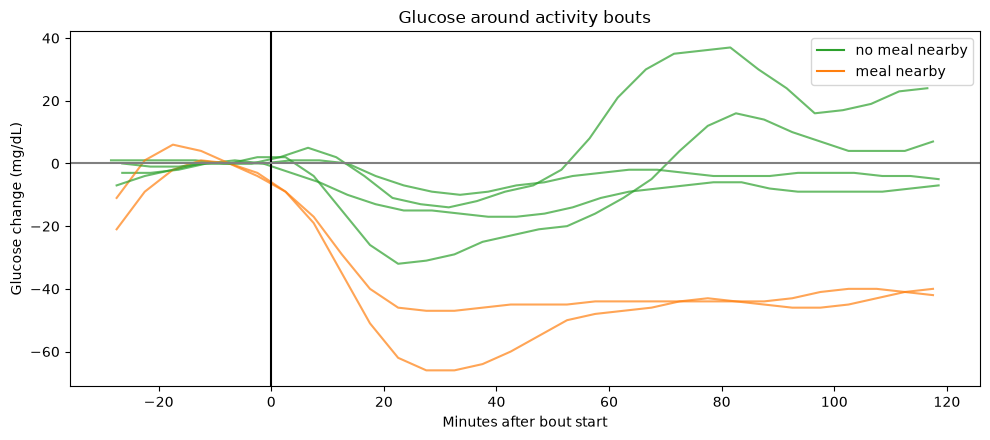

Bout size (intensity × duration) vs lowest glucose change: rho = -0.37 (p = 0.468)


In [32]:
if len(bout_resp):
    print("Median glucose change after bout start:")
    print(bout_resp.groupby("meal_nearby")[["change_30", "change_60", "change_120", "min_change_2h"]]
          .median().rename(index={False: "no meal nearby", True: "meal nearby"}).round(1))

    fig, ax = plt.subplots(figsize=(10, 4.5))
    for _, r in bout_resp.iterrows():
        w_ = grid[r["start"] - pd.Timedelta("30min"): r["start"] + pd.Timedelta("2h")]
        x = (w_.index - r["start"]).total_seconds() / 60
        ax.plot(x, w_.values - r["baseline"], color="tab:orange" if r["meal_nearby"] else "tab:green", alpha=0.7)
    ax.plot([], [], color="tab:green", label="no meal nearby")
    ax.plot([], [], color="tab:orange", label="meal nearby")
    ax.axvline(0, color="black")
    ax.axhline(0, color="gray")
    ax.set_xlabel("Minutes after bout start")
    ax.set_ylabel("Glucose change (mg/dL)")
    ax.set_title("Glucose around activity bouts")
    ax.legend()
    plt.tight_layout()
    plt.show()

    rho, p = stats.spearmanr(bout_resp["mean_enmo"] * bout_resp["minutes"], bout_resp["min_change_2h"]) \
        if len(bout_resp) >= 5 else (np.nan, np.nan)
    print(f"Bout size (intensity × duration) vs lowest glucose change: rho = {rho:.2f} (p = {p:.3f})")

## Q8 (added): Does heart rate rise when glucose drops?

When glucose falls, the body defends itself by releasing hormones such as **adrenaline**, which raise glucose but also raise heart rate. In people with diabetes, a racing heart is a classic warning sign of a low. In people without diabetes, the effect during mild dips is usually small.

We compare HR in three windows around each dip's nadir: before (−60 to −30 min), at the nadir (±15 min), and after (+15 to +45 min). To avoid mixing this up with exercise, we look separately at **rest dips** (no activity in the 90 min before), because during exercise HR is already high for another reason.

In [33]:
def hr_window(t, a, b):
    seg = wear.loc[t + pd.Timedelta(minutes=a): t + pd.Timedelta(minutes=b), "hr"]
    return seg.mean() if seg.count() >= (b - a) * 0.5 else np.nan

dips["hr_pre"] = [hr_window(t, -60, -30) for t in dips["nadir_time"]]
dips["hr_nadir"] = [hr_window(t, -15, 15) for t in dips["nadir_time"]]
dips["hr_post"] = [hr_window(t, 15, 45) for t in dips["nadir_time"]]
dips["hr_change_at_nadir"] = dips["hr_nadir"] - dips["hr_pre"]
dips["rest_dip"] = dips["active_min_before"] == 0

for label, sub in [("All dips", dips), ("Rest dips", dips[dips["rest_dip"]])]:
    s = sub["hr_change_at_nadir"].dropna()
    if len(s) >= 3:
        w_stat, p = stats.wilcoxon(s)
        print(f"{label:10s} n = {len(s):2d} | median HR change at nadir: {s.median():+.1f} bpm (Wilcoxon p = {p:.3f})")
    else:
        print(f"{label:10s} n = {len(s)}: not enough dips with HR data")

All dips   n = 33 | median HR change at nadir: +2.2 bpm (Wilcoxon p = 0.071)
Rest dips  n = 19 | median HR change at nadir: +1.3 bpm (Wilcoxon p = 0.922)


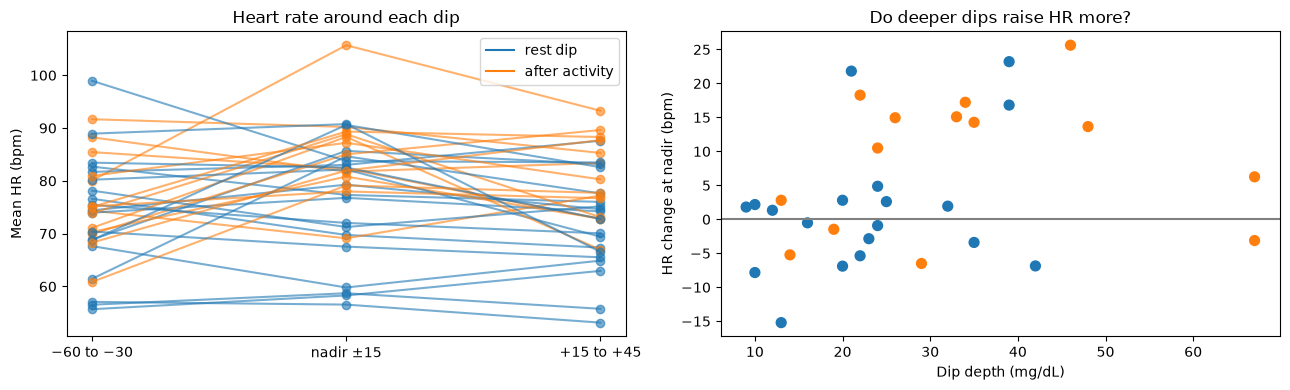

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sub = dips.dropna(subset=["hr_pre", "hr_nadir", "hr_post"])
for _, r in sub.iterrows():
    axes[0].plot([0, 1, 2], [r["hr_pre"], r["hr_nadir"], r["hr_post"]],
                 "o-", color="tab:blue" if r["rest_dip"] else "tab:orange", alpha=0.6)
axes[0].plot([], [], color="tab:blue", label="rest dip")
axes[0].plot([], [], color="tab:orange", label="after activity")
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(["−60 to −30", "nadir ±15", "+15 to +45"])
axes[0].set_ylabel("Mean HR (bpm)")
axes[0].set_title("Heart rate around each dip")
axes[0].legend()

axes[1].scatter(dips["drop"], dips["hr_change_at_nadir"], c=np.where(dips["rest_dip"], "tab:blue", "tab:orange"), s=50)
axes[1].axhline(0, color="gray")
axes[1].set_xlabel("Dip depth (mg/dL)")
axes[1].set_ylabel("HR change at nadir (bpm)")
axes[1].set_title("Do deeper dips raise HR more?")
plt.tight_layout()
plt.show()

---
# Part D: Dips and meals

## Q9: Do dips follow large spikes?

A big meal spike can trigger more insulin than needed, pushing glucose **below** its starting level afterwards (a reactive dip). For each dip we check:
- was a meal logged in the 4 hours before the nadir?
- how big was the rise into the peak that came before the dip? (peak minus the lowest point in the 2 h before that peak)

If reactive dips are common, larger spikes should be followed by deeper dips.

In [35]:
pre_rise, meal_before, meal_food, mins_after_meal = [], [], [], []
for _, d in dips.iterrows():
    pk_t = d["pre_max_time"]
    pre_rise.append(d["pre_max"] - grid[pk_t - pd.Timedelta("2h"): pk_t].min())
    m = meals[(meals["time"] >= d["nadir_time"] - pd.Timedelta(minutes=LOOKBACK_MEAL)) &
              (meals["time"] <= d["nadir_time"])]
    meal_before.append(len(m) > 0)
    meal_food.append(str(m.iloc[-1]["foods"])[:35] if len(m) else "")
    mins_after_meal.append((d["nadir_time"] - m["time"].max()).total_seconds() / 60 if len(m) else np.nan)

dips["spike_before"] = pre_rise
dips["meal_before"] = meal_before
dips["last_meal"] = meal_food
dips["min_after_meal"] = mins_after_meal
dips["below_pre_meal"] = False
for i, d in dips[dips["meal_before"]].iterrows():
    mt = meals.loc[(meals["time"] <= d["nadir_time"]) &
                   (meals["time"] >= d["nadir_time"] - pd.Timedelta(minutes=LOOKBACK_MEAL)), "time"].max()
    base = grid[mt - pd.Timedelta("30min"): mt].median()
    dips.loc[i, "below_pre_meal"] = d["nadir"] < base - 10

print(f"Dips with a meal in the 4 h before: {int(dips['meal_before'].sum())} of {len(dips)}")
print(f"  of which glucose fell > 10 mg/dL below the pre-meal level: {int(dips['below_pre_meal'].sum())}")
print(f"Median time from meal to dip nadir: {dips['min_after_meal'].median():.0f} min")

d_ = dips[["spike_before", "drop"]].dropna()
if len(d_) >= 5:
    rho, p = stats.spearmanr(d_["spike_before"], d_["drop"])
    print(f"Spike size before vs dip depth: Spearman rho = {rho:.2f} (p = {p:.3f})")

Dips with a meal in the 4 h before: 33 of 45
  of which glucose fell > 10 mg/dL below the pre-meal level: 18
Median time from meal to dip nadir: 72 min
Spike size before vs dip depth: Spearman rho = 0.76 (p = 0.000)


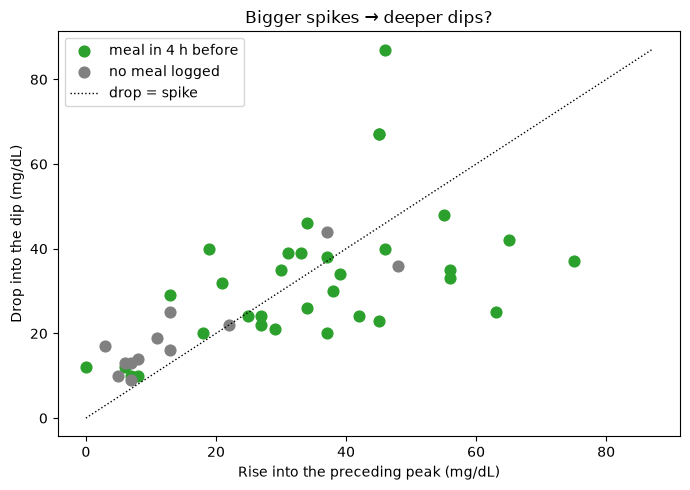

Points above the dotted line fell further than they rose, i.e. they ended below the starting level.


In [36]:
fig, ax = plt.subplots(figsize=(7, 5))
for mb, col, lab in [(True, "tab:green", "meal in 4 h before"), (False, "gray", "no meal logged")]:
    s = dips[dips["meal_before"] == mb]
    ax.scatter(s["spike_before"], s["drop"], color=col, s=60, label=lab)
lim = max(dips["spike_before"].max(), dips["drop"].max()) if len(dips) else 50
ax.plot([0, lim], [0, lim], "k:", lw=1, label="drop = spike")
ax.set_xlabel("Rise into the preceding peak (mg/dL)")
ax.set_ylabel("Drop into the dip (mg/dL)")
ax.set_title("Bigger spikes → deeper dips?")
ax.legend()
plt.tight_layout()
plt.show()
print("Points above the dotted line fell further than they rose, i.e. they ended below the starting level.")

## Q10 (added): Possible compression lows

When someone sleeps lying on the arm with the CGM sensor, pressure squeezes fluid away from the sensor and it **reads falsely low**. The pattern is distinctive:
- during sleep or at night
- the wrist is very still
- a **fast fall** (≥ 1.5 mg/dL/min) followed by a **fast rebound** (≥ 15 mg/dL within 30 min) once the person shifts position

Real lows rarely recover that quickly without food. Flagged dips are not proof of an artifact, but they should be treated with caution.

In [37]:
def motion_around(t, minutes=30):
    seg = wear.loc[t - pd.Timedelta(minutes=minutes): t + pd.Timedelta(minutes=minutes)]
    return seg["enmo"].mean() if seg["enmo"].count() >= minutes else np.nan

dips["motion_around"] = [motion_around(t) for t in dips["nadir_time"]]
dips["during_sleep"] = wear["asleep"].reindex(dips["nadir_time"].dt.floor("min")).fillna(False).astype(bool).values

dips["compression_suspect"] = (
    (dips["during_sleep"] | dips["night"])
    & (dips["motion_around"] < SLEEP_ENMO * 1.5)
    & (dips["max_fall_rate"] <= -1.5)
    & (dips["rebound_30min"] >= 15)
)
print(f"Dips flagged as possible compression lows: {int(dips['compression_suspect'].sum())} of {len(dips)}")
dips.loc[dips["compression_suspect"], ["nadir_time", "nadir", "drop", "max_fall_rate", "rebound_30min",
                                        "motion_around", "during_sleep"]].round(2)

Dips flagged as possible compression lows: 1 of 45


,nadir_time,nadir,drop,max_fall_rate,rebound_30min,motion_around,during_sleep
1,2020-02-14 04:28:32,66.0,25.0,-2.2,27.0,7.79,True


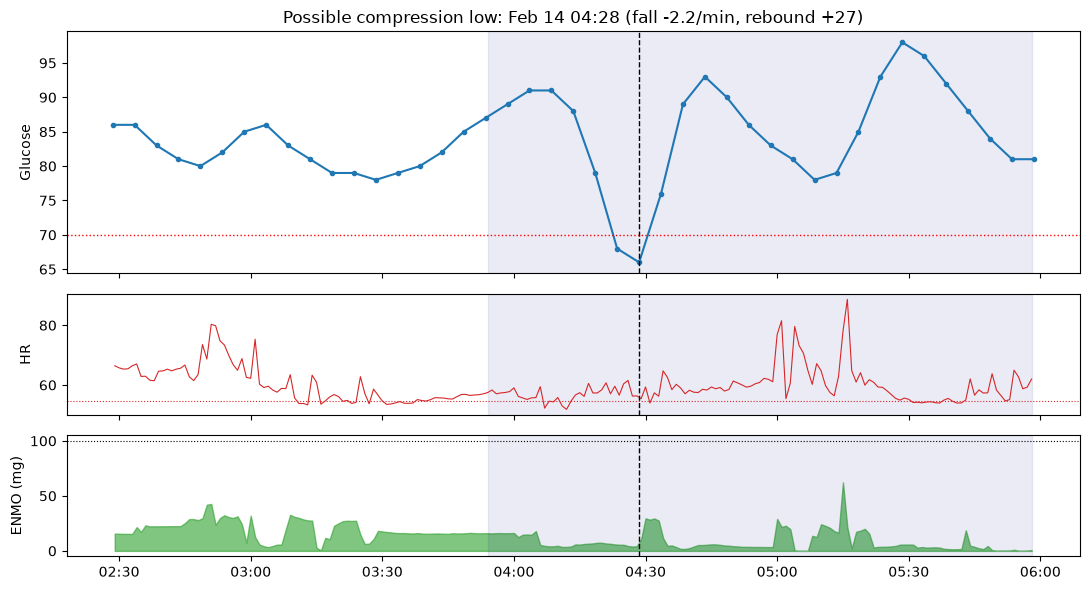

In [38]:
for _, d in dips[dips["compression_suspect"]].head(4).iterrows():
    plot_context(d["nadir_time"], before=120, after=90,
                 title=f"Possible compression low: {d['nadir_time']:%b %d %H:%M} "
                       f"(fall {d['max_fall_rate']:.1f}/min, rebound +{d['rebound_30min']:.0f})")
if not dips["compression_suspect"].any():
    print("No dips matched the compression-low pattern.")

---
# Part E: Putting it together

## Q11 (added): The most likely cause of each dip

Each dip gets one label, checked in this order:

| Label | Rule |
|---|---|
| possible sensor compression | flagged in Q10 |
| post-meal + activity | meal in the 4 h before **and** activity percentile ≥ 80 or ≥ 10 active minutes |
| post-meal (reactive) | meal in the 4 h before and the preceding spike was ≥ 20 mg/dL |
| post-activity | activity percentile ≥ 80 or ≥ 10 active minutes in the 90 min before |
| overnight drift | at night or during sleep, none of the above |
| unexplained | everything else (unlogged food, stress, illness, or sensor noise) |

These are reasoned guesses, not diagnoses, but they summarise everything this notebook has found.

likely_cause
post-meal (reactive)           18
post-meal + activity           10
unexplained                    10
post-activity                   4
overnight drift                 2
possible sensor compression     1


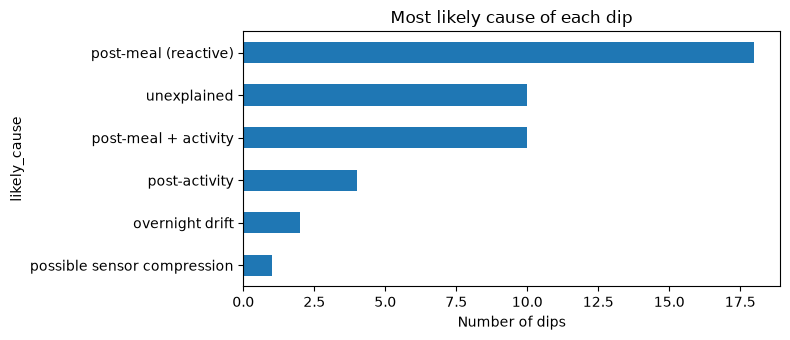

In [39]:
def classify(d):
    active_before = (d["activity_percentile"] >= 80) or (d["active_min_before"] >= 10)
    if d["compression_suspect"]:
        return "possible sensor compression"
    if d["meal_before"] and active_before:
        return "post-meal + activity"
    if d["meal_before"] and d["spike_before"] >= 20:
        return "post-meal (reactive)"
    if active_before:
        return "post-activity"
    if d["night"] or d["during_sleep"]:
        return "overnight drift"
    return "unexplained"

dips["likely_cause"] = dips.apply(classify, axis=1)
causes = dips["likely_cause"].value_counts()
print(causes.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
causes.sort_values().plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Number of dips")
ax.set_title("Most likely cause of each dip")
plt.tight_layout()
plt.show()

In [40]:
cols = ["nadir_time", "nadir", "drop", "likely_cause", "last_meal", "min_after_meal",
        "active_min_before", "activity_percentile", "hr_change_at_nadir", "during_sleep"]
dips[cols].round(1)

,nadir_time,nadir,drop,likely_cause,last_meal,min_after_meal,active_min_before,activity_percentile,hr_change_at_nadir,during_sleep
0,2020-02-13 21:18:32,82.0,42.0,post-meal + activity,"Chicken Leg, Asparagus",48.5,0.0,80.8,-6.9,False
1,2020-02-14 04:28:32,66.0,25.0,possible sensor compression,,NaN,0.0,68.4,2.6,True
2,2020-02-14 09:13:32,83.0,39.0,post-meal (reactive),"Natrel Lactose Free 2 Percent, Stan",123.5,0.0,0.0,16.8,False
3,2020-02-14 12:03:32,88.0,22.0,post-meal (reactive),Breakfast Trail Mix,145.5,0.0,21.4,-5.4,False
4,2020-02-14 17:58:32,84.0,14.0,unexplained,,NaN,1.0,60.0,-5.2,False
5,2020-02-15 08:43:32,62.0,40.0,unexplained,Spinach Smoothie,73.5,NaN,NaN,NaN,False
6,2020-02-15 15:33:32,71.0,29.0,post-meal + activity,"Babel Cheese, Breakfast Trail Mix",3.5,11.0,100.0,-6.5,False
7,2020-02-15 18:43:32,79.0,30.0,post-meal (reactive),"Babel Cheese, Breakfast Trail Mix",193.5,NaN,NaN,NaN,False
8,2020-02-16 06:43:32,87.0,17.0,unexplained,,NaN,NaN,NaN,NaN,False
9,2020-02-16 08:08:32,46.0,87.0,post-meal (reactive),"Natrel Lactose Free 2 Percent, Stan",68.5,NaN,NaN,NaN,False


### Each dip in context

Glucose, HR, and movement for the deepest dips, labelled with their likely cause. Change `N_PLOTS` to see more.

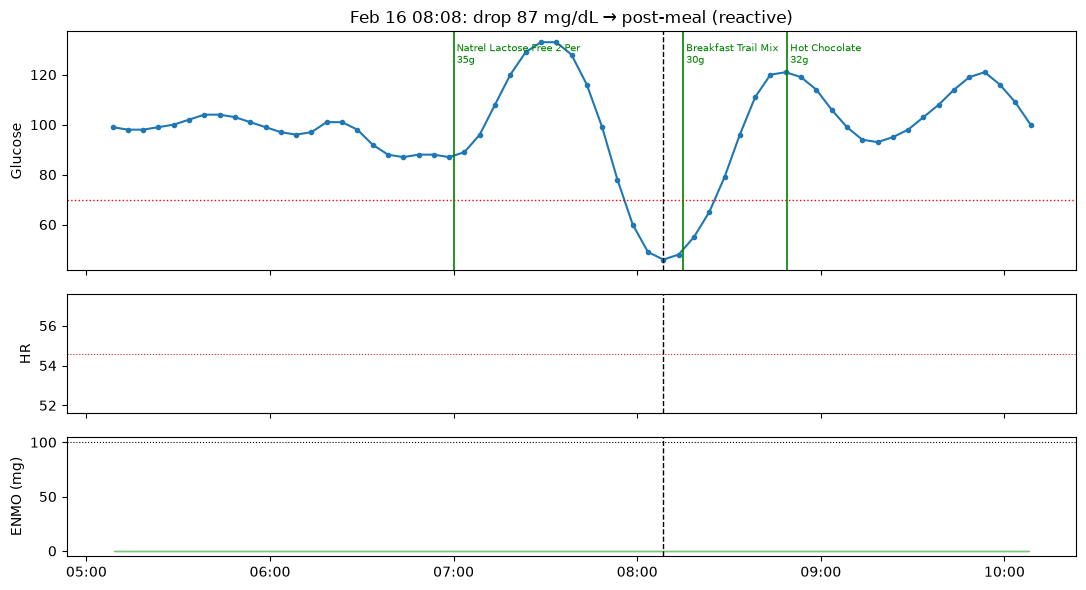

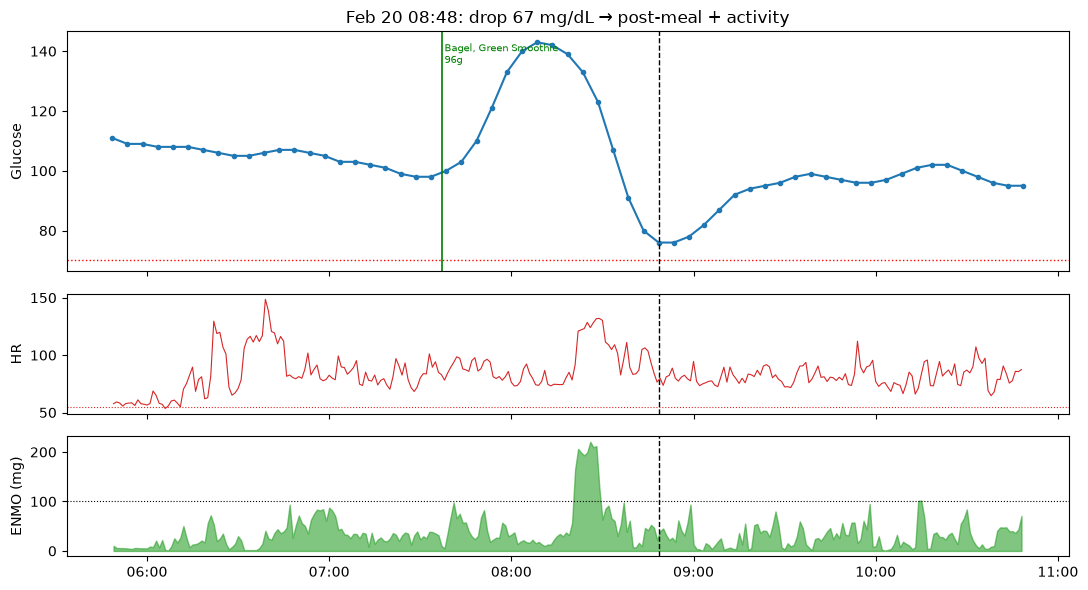

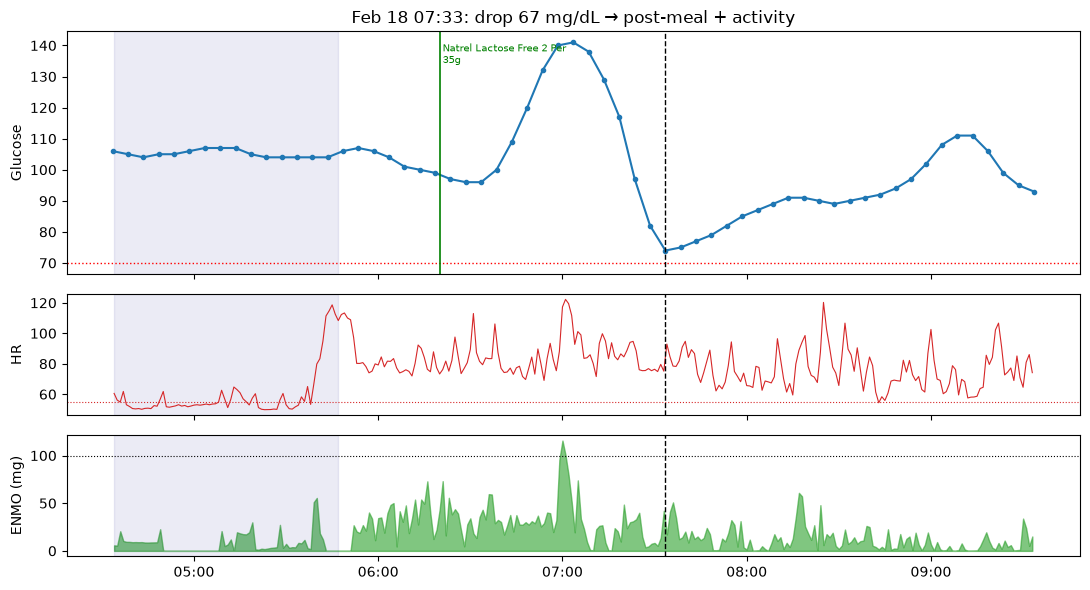

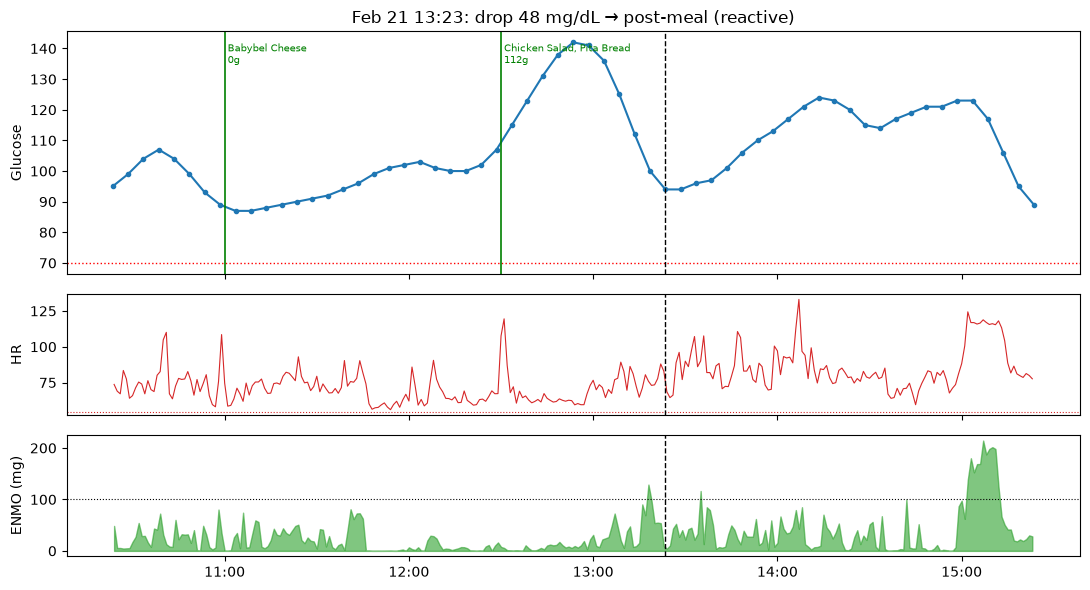

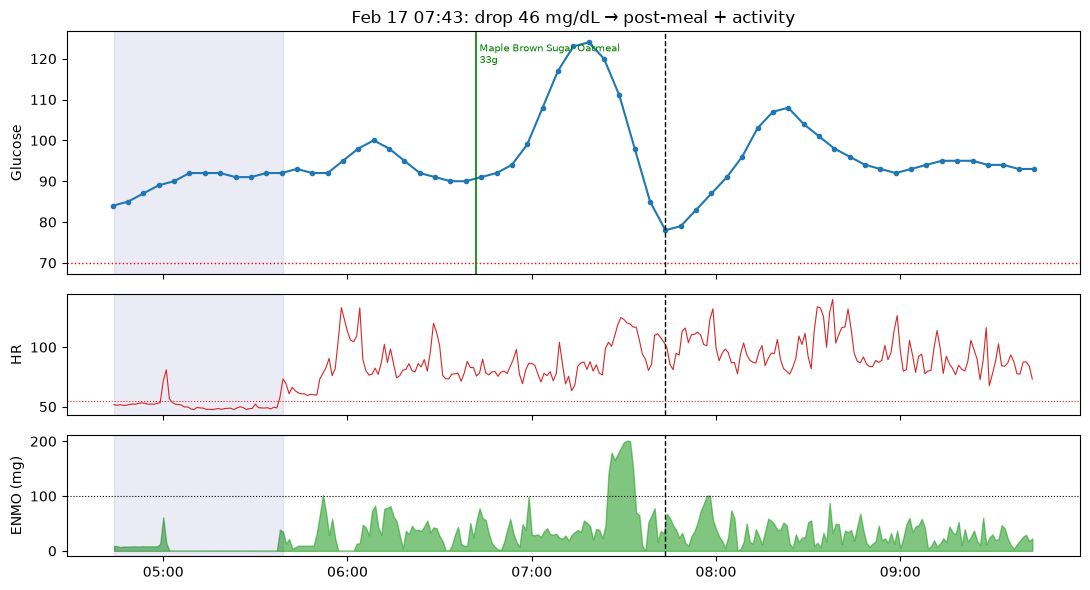

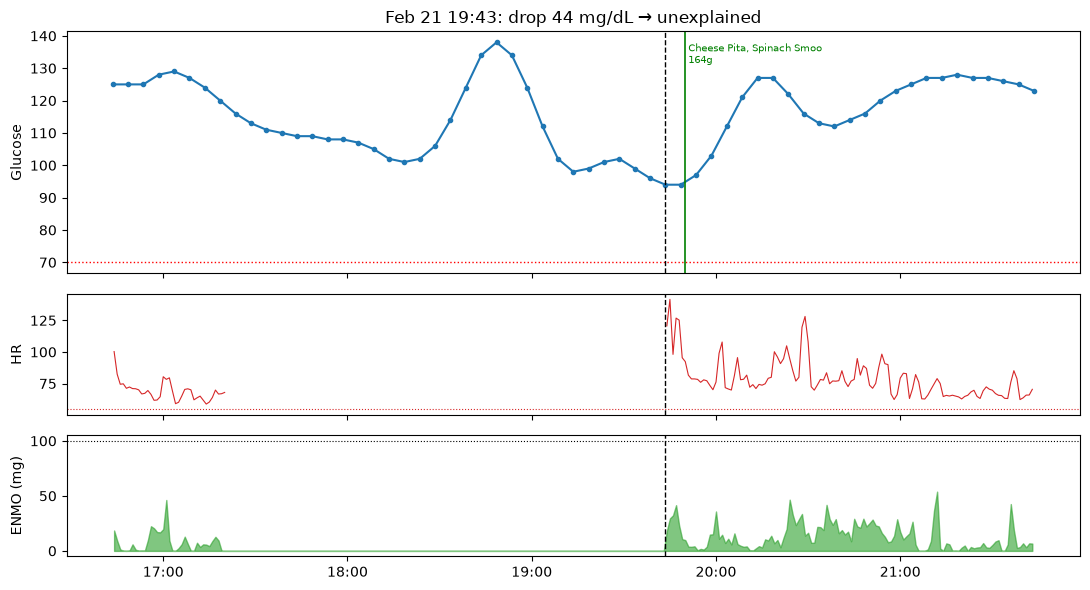

In [41]:
N_PLOTS = 6
for _, d in dips.sort_values("drop", ascending=False).head(N_PLOTS).iterrows():
    plot_context(d["nadir_time"], title=f"{d['nadir_time']:%b %d %H:%M}: drop {d['drop']:.0f} mg/dL → {d['likely_cause']}")

---
## Summary

All Stage 7 answers in one table. The dip table, activity bouts, and 1-minute sensor summaries are saved for Stage 8 and the HR–glucose correlation.

In [42]:
summary = pd.Series({
    "% time < 70": round((valid < LOW1).mean() * 100, 2),
    "% time < 54": round((valid < LOW2).mean() * 100, 2),
    "Runs < 70 / clinical episodes": f"{len(low70)} / {int(low70['episode'].sum())}",
    "Relative dips": len(dips),
    "Dips per day": round(len(dips) / grid.index.normalize().nunique(), 1),
    "Night dips (00–06)": int(dips["night"].sum()),
    "CGM–wristband overlap (%)": round(overlap.mean() * 100, 1),
    "Resting HR (bpm)": round(resting_hr, 0),
    "Mean active min/day": round(daily_act["active min"].mean(), 0),
    "Activity bouts": len(bouts),
    "Avg sleep period (h)": round(sleep["hours"].mean(), 1) if len(sleep) else np.nan,
    "Median activity percentile before dips": round(dips["activity_percentile"].median(), 0),
    "Median HR change at nadir (bpm)": round(dips["hr_change_at_nadir"].median(), 1),
    "Dips with a meal in 4 h before": int(dips["meal_before"].sum()),
    "Possible compression lows": int(dips["compression_suspect"].sum()),
    "Most common cause": causes.index[0] if len(causes) else "",
}, name=PID)
summary.to_frame()

,001
% time < 70,0.86
% time < 54,0.12
Runs < 70 / clinical episodes,4 / 3
Relative dips,45
Dips per day,4.5
Night dips (00–06),3
CGM–wristband overlap (%),80.0
Resting HR (bpm),55.0
Mean active min/day,14.0
Activity bouts,6


In [43]:
summary.to_frame().T.rename_axis("participant").to_csv(f"stage7_summary_{PID}.csv")
dips.round(2).to_csv(f"stage7_dips_{PID}.csv", index=False)
bouts.round(2).to_csv(f"stage7_activity_bouts_{PID}.csv", index=False)
if len(sleep):
    sleep.to_csv(f"stage7_sleep_{PID}.csv")
wear.round(2).to_csv(f"wearable_1min_{PID}.csv")
print("Saved stage7_summary, stage7_dips, stage7_activity_bouts, stage7_sleep, wearable_1min")

Saved stage7_summary, stage7_dips, stage7_activity_bouts, stage7_sleep, wearable_1min
